# [3-b] CNN 입력 크기 64 vs 128 비교 (+ Early Stopping)

[3]의 CNN은 64×64 입력에서 val acc 0.85였고, **시작 자세 ↔ 중간 자세**를 가장 많이 헷갈렸어요.
두 자세는 팔 높이만 조금 달라서, 사진을 크게(128×128) 넣으면 더 잘 구분할지 확인합니다.

- 모델 구조는 [3]과 같고, 입력 크기에 맞춰 `fc1` 입력 개수만 달라짐
- 둘 다 Early Stopping (val loss가 5번 연속 안 좋아지면 멈춤, 제일 좋았던 모델 저장)

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [2]:
# 검증은 A040 선수 (tk_2, tk_3와 똑같이 나눔 → 결과 비교 가능)
VAL_PERSON = "A040"

def make_loaders(img_size):
    transform = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
    ])
    dataset = datasets.ImageFolder("tk_crops", transform=transform)
    train_idx = [i for i, (p, _) in enumerate(dataset.samples) if VAL_PERSON not in os.path.basename(p)]
    val_idx = [i for i, (p, _) in enumerate(dataset.samples) if VAL_PERSON in os.path.basename(p)]
    train_loader = DataLoader(Subset(dataset, train_idx), batch_size=32, shuffle=True)
    val_loader = DataLoader(Subset(dataset, val_idx), batch_size=32, shuffle=False)
    return dataset.classes, train_loader, val_loader

In [3]:
classes, train_loader_64, val_loader_64 = make_loaders(64)
_, train_loader_128, val_loader_128 = make_loaders(128)
print("클래스:", classes)

images, _ = next(iter(train_loader_128))
print("128 배치:", images.shape)     # (32, 3, 128, 128)

클래스: ['1_start', '2_middle', '3_end']
128 배치: torch.Size([32, 3, 128, 128])


In [4]:
criterion = nn.CrossEntropyLoss()

def train_model(model, optimizer, train_loader, val_loader, save_path, max_epochs=50, patience=5):
    """학습 + Early Stopping
    - val loss가 좋아질 때마다 모델을 파일(save_path)로 저장
    - patience번 연속으로 안 좋아지면 학습을 멈춤
    - 끝나면 제일 좋았던 모델을 다시 불러옴
    """
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_loss = float("inf")    # 지금까지 제일 낮은 val loss (처음엔 무한대)
    wait = 0                    # 몇 번 연속으로 안 좋아졌는지

    for epoch in range(max_epochs):
        # ----- 학습 -----
        model.train()
        total_loss, correct, total = 0, 0, 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
        train_loss, train_acc = total_loss / total, correct / total

        # ----- 검증 -----
        model.eval()
        total_loss, correct, total = 0, 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                total_loss += criterion(outputs, labels).item() * labels.size(0)
                correct += (outputs.argmax(1) == labels).sum().item()
                total += labels.size(0)
        val_loss, val_acc = total_loss / total, correct / total

        history["train_loss"].append(train_loss); history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss); history["val_acc"].append(val_acc)
        msg = f"Epoch {epoch + 1:2d} | train loss {train_loss:.4f} acc {train_acc:.4f} | val loss {val_loss:.4f} acc {val_acc:.4f}"

        # ----- Early Stopping -----
        if val_loss < best_loss:
            best_loss = val_loss
            wait = 0
            torch.save(model.state_dict(), save_path)     # 제일 좋은 모델 저장
            msg += "  ← best 저장"
        else:
            wait += 1
            msg += f"  (좋아지지 않음 {wait}/{patience})"
        print(msg)
        if wait >= patience:
            print(f"→ {patience}번 연속 val loss가 좋아지지 않아서 {epoch + 1} epoch에서 멈춤")
            break

    model.load_state_dict(torch.load(save_path))          # 제일 좋았던 모델로 되돌리기
    return history

In [5]:
def evaluate(model, val_loader, n_classes=3):
    """정확도와 혼동행렬 (행 = 정답, 열 = 예측)"""
    model.eval()
    cm = np.zeros((n_classes, n_classes), dtype=int)
    with torch.no_grad():
        for images, labels in val_loader:
            preds = model(images.to(device)).argmax(1).cpu()
            for t, p in zip(labels, preds):
                cm[t, p] += 1
    acc = np.trace(cm) / cm.sum()       # 대각선 합 / 전체
    return acc, cm

def plot_cm(cm, classes, title):
    plt.imshow(cm, cmap="Blues")
    plt.xticks(range(len(classes)), classes); plt.yticks(range(len(classes)), classes)
    plt.xlabel("예측"); plt.ylabel("정답"); plt.title(title)
    for i in range(len(classes)):
        for j in range(len(classes)):
            plt.text(j, i, cm[i, j], ha="center", va="center")

## CNN (입력 크기를 받아서 fc1 크기를 자동으로 맞춤)

In [6]:
class CNN(nn.Module):
    def __init__(self, img_size):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.relu = nn.ReLU()
        # MaxPool을 3번 → 가로세로가 1/8로 줄어듦 (64 → 8, 128 → 16)
        last = img_size // 8
        self.fc1 = nn.Linear(64 * last * last, 128)
        self.fc2 = nn.Linear(128, 3)

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.pool(self.relu(self.conv3(x)))
        x = x.view(x.size(0), -1)
        x = self.relu(self.fc1(x))
        return self.fc2(x)

# shape 비교
for size in [64, 128]:
    m = CNN(size).to(device)
    x = torch.randn(1, 3, size, size).to(device)
    x = m.pool(m.relu(m.conv1(x))); s1 = tuple(x.shape)
    x = m.pool(m.relu(m.conv2(x))); s2 = tuple(x.shape)
    x = m.pool(m.relu(m.conv3(x))); s3 = tuple(x.shape)
    n_param = sum(p.numel() for p in m.parameters())
    print(f"입력 {size}: conv1 {s1} → conv2 {s2} → conv3 {s3} → 펼침 {x.view(1, -1).shape[1]} | 파라미터 {n_param:,}")

입력 64: conv1 (1, 16, 32, 32) → conv2 (1, 32, 16, 16) → conv3 (1, 64, 8, 8) → 펼침 4096 | 파라미터 548,387
입력 128: conv1 (1, 16, 64, 64) → conv2 (1, 32, 32, 32) → conv3 (1, 64, 16, 16) → 펼침 16384 | 파라미터 2,121,251


## 64 × 64

In [7]:
results = {}
torch.manual_seed(42)
model_64 = CNN(64).to(device)
opt_64 = optim.Adam(model_64.parameters(), lr=0.001)
results["CNN 64"] = train_model(model_64, opt_64, train_loader_64, val_loader_64, "best_cnn_64.pth")

Epoch  1 | train loss 1.1004 acc 0.3880 | val loss 1.0733 acc 0.5189  ← best 저장
Epoch  2 | train loss 0.9429 acc 0.5423 | val loss 0.9300 acc 0.5000  ← best 저장
Epoch  3 | train loss 0.7758 acc 0.6377 | val loss 0.7570 acc 0.7273  ← best 저장
Epoch  4 | train loss 0.6465 acc 0.7138 | val loss 0.6413 acc 0.6932  ← best 저장
Epoch  5 | train loss 0.4878 acc 0.8081 | val loss 0.6330 acc 0.6894  ← best 저장
Epoch  6 | train loss 0.4206 acc 0.8296 | val loss 0.5608 acc 0.7576  ← best 저장
Epoch  7 | train loss 0.3124 acc 0.8682 | val loss 0.4996 acc 0.7917  ← best 저장
Epoch  8 | train loss 0.2906 acc 0.8832 | val loss 0.4678 acc 0.8182  ← best 저장
Epoch  9 | train loss 0.2047 acc 0.9228 | val loss 0.5075 acc 0.7879  (좋아지지 않음 1/5)
Epoch 10 | train loss 0.1869 acc 0.9228 | val loss 0.4783 acc 0.8485  (좋아지지 않음 2/5)
Epoch 11 | train loss 0.2203 acc 0.9110 | val loss 0.4677 acc 0.8220  ← best 저장
Epoch 12 | train loss 0.1321 acc 0.9571 | val loss 0.4616 acc 0.8485  ← best 저장
Epoch 13 | train loss 0.0981 acc

## 128 × 128

In [8]:
torch.manual_seed(42)
model_128 = CNN(128).to(device)
opt_128 = optim.Adam(model_128.parameters(), lr=0.001)
results["CNN 128"] = train_model(model_128, opt_128, train_loader_128, val_loader_128, "best_cnn_128.pth")

Epoch  1 | train loss 0.9685 acc 0.5230 | val loss 0.7824 acc 0.6515  ← best 저장
Epoch  2 | train loss 0.6481 acc 0.7235 | val loss 0.5678 acc 0.7917  ← best 저장
Epoch  3 | train loss 0.4193 acc 0.8274 | val loss 0.4806 acc 0.8182  ← best 저장
Epoch  4 | train loss 0.3669 acc 0.8542 | val loss 0.5726 acc 0.7803  (좋아지지 않음 1/5)
Epoch  5 | train loss 0.2836 acc 0.8864 | val loss 0.4030 acc 0.8447  ← best 저장
Epoch  6 | train loss 0.2184 acc 0.9196 | val loss 0.3770 acc 0.8409  ← best 저장
Epoch  7 | train loss 0.1657 acc 0.9378 | val loss 0.3795 acc 0.8561  (좋아지지 않음 1/5)
Epoch  8 | train loss 0.0906 acc 0.9657 | val loss 0.4168 acc 0.8447  (좋아지지 않음 2/5)
Epoch  9 | train loss 0.0678 acc 0.9775 | val loss 0.4141 acc 0.8447  (좋아지지 않음 3/5)
Epoch 10 | train loss 0.0435 acc 0.9871 | val loss 0.4829 acc 0.8371  (좋아지지 않음 4/5)
Epoch 11 | train loss 0.0940 acc 0.9668 | val loss 0.4078 acc 0.8371  (좋아지지 않음 5/5)
→ 5번 연속 val loss가 좋아지지 않아서 11 epoch에서 멈춤


## 비교

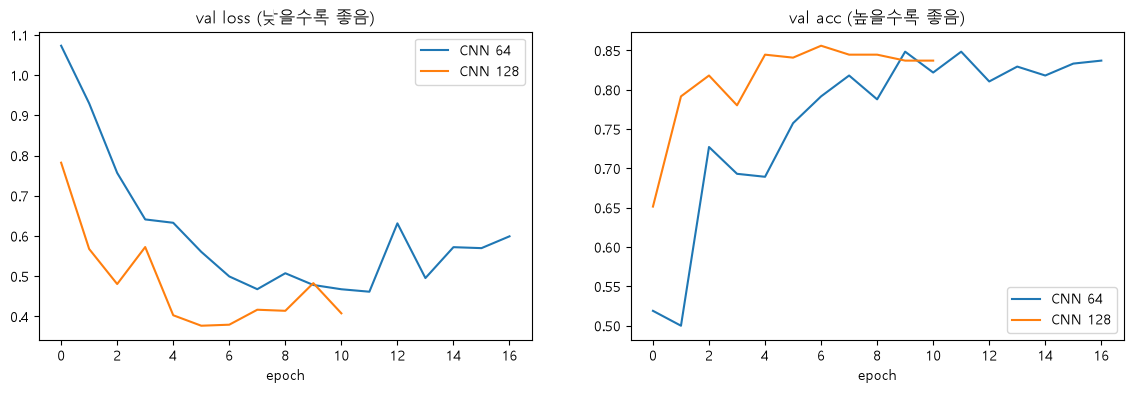

In [9]:
plt.figure(figsize=(14, 4))
plt.subplot(1, 2, 1)
for name, h in results.items():
    plt.plot(h["val_loss"], label=name)
plt.title("val loss (낮을수록 좋음)"); plt.xlabel("epoch"); plt.legend()
plt.subplot(1, 2, 2)
for name, h in results.items():
    plt.plot(h["val_acc"], label=name)
plt.title("val acc (높을수록 좋음)"); plt.xlabel("epoch"); plt.legend()
plt.show()

버전       | 학습한 epoch | 최종 val acc | 시작 / 중간 / 끝 정확도
CNN 64   |          17 | 0.8485       | 0.88 / 0.76 / 0.91
CNN 128  |          11 | 0.8409       | 0.81 / 0.77 / 0.94


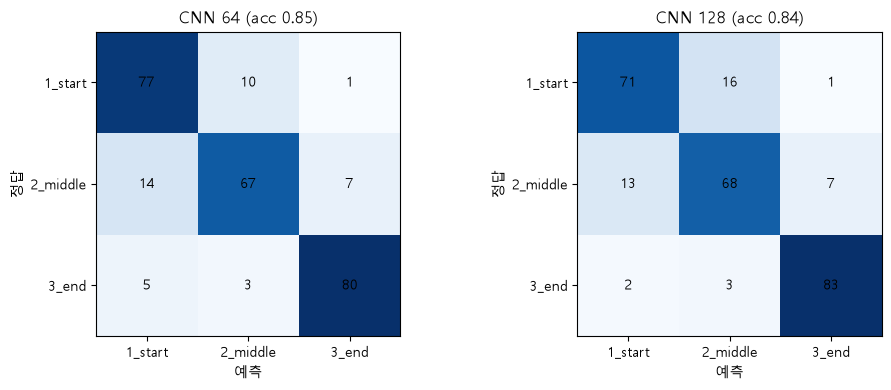

In [10]:
print(f"{'버전':8s} | 학습한 epoch | 최종 val acc | 시작 / 중간 / 끝 정확도")
plt.figure(figsize=(10, 4))
for k, (name, m, loader) in enumerate([("CNN 64", model_64, val_loader_64), ("CNN 128", model_128, val_loader_128)]):
    acc, cm = evaluate(m, loader)
    per_class = " / ".join(f"{cm[i, i] / cm[i].sum():.2f}" for i in range(3))
    print(f"{name:8s} | {len(results[name]['val_acc']):11d} | {acc:.4f}       | {per_class}")
    plt.subplot(1, 2, k + 1)
    plot_cm(cm, classes, f"{name} (acc {acc:.2f})")
plt.tight_layout(); plt.show()

In [11]:
# 128 모델로 val 사진 8장 예측 (빨간 제목 = 틀림)
images, labels = next(iter(val_loader_128))
model_128.eval()
with torch.no_grad():
    probs = torch.softmax(model_128(images.to(device)), dim=1).cpu()
preds = probs.argmax(1)

plt.figure(figsize=(14, 3.5))
for i in range(8):
    plt.subplot(1, 8, i + 1)
    plt.imshow(images[i].permute(1, 2, 0) * 0.5 + 0.5)
    color = "black" if preds[i] == labels[i] else "red"
    plt.title(f"정답 {classes[labels[i]]}\n예측 {classes[preds[i]]}\n{probs[i, preds[i]]:.0%}", fontsize=8, color=color)
    plt.axis("off")
plt.show()

## 생각해볼 것
1. 128로 키웠더니 **시작 ↔ 중간** 헷갈림이 줄었어? 혼동행렬 왼쪽 위 2×2 부분을 비교해보기
2. 파라미터 수가 왜 늘었을까? (conv 층은 그대로인데 어느 층이 커졌지?)
3. 학습 시간은 얼마나 늘었어? 정확도가 오른 만큼 가치가 있을까?
4. 저장된 `best_cnn_128.pth`를 나중에 다시 불러와서 쓰려면 어떤 코드가 필요할까?